# 8. 😎 Build the face effect from start to finish

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/8_face_models_and_effects.ipynb)

## Goal

Build the AR lip-color effect previewed in notebook 1: **detect → crop → find landmarks → mask → edit → retrace**. Inspect the intermediate results, then explore full-photo segmentation as another way to place an effect. By the end, you can explain every step and replace the portrait with your own.

## Setup

Run all cells from top to bottom in a fresh kernel. The setup cell installs Landpy 0.1.0 if needed. A CPU is enough. Use Python 3.10–3.13 and the optional TensorFlow dependencies.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.0':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.0'])
import numpy as np
import matplotlib.pyplot as plt
from landpy import ImageLand, Filter, Debugger


The model examples need the optional TensorFlow dependencies. Model weights download only when a model is constructed. Reuse the cache on later runs.

In [2]:
import importlib.util
if importlib.util.find_spec('tensorflow') is None or importlib.util.find_spec('tf_keras') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy[tensorflow]==0.1.0'])
import warnings
warnings.filterwarnings("ignore", message=r"(?s).*tf.lite.Interpreter is deprecated.*", category=UserWarning)

## Steps

### 1. Load a reproducible example

The image below is the original repository test fixture. Its original photographer/license was not recorded. Use your own image when redistributing results. For your own image, replace this loading cell with `ImageLand("your-image.jpg")`.

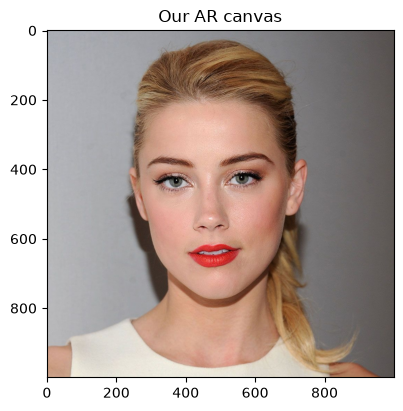

In [3]:
from pathlib import Path
import requests
local = Path('examples/assets/face.jpg')
if not local.exists():
    local = Path('../examples/assets/face.jpg')
if local.exists():
    photo = ImageLand(local)
else:
    from io import BytesIO
    from PIL import Image
    response = requests.get('https://raw.githubusercontent.com/bateni1380/landpy/master/examples/assets/face.jpg', timeout=30)
    response.raise_for_status()
    photo = ImageLand(Image.open(BytesIO(response.content)))
photo.show('Our AR canvas');
original = photo.get_image().copy()

### 2. Detect a face and six keypoints

FaceTracker uses short-range BlazeFace. Scores are sigmoid probabilities and overlapping boxes are suppressed. `threshold` returns all qualifying detections; `top_k` limits them. `FacePoints` combines a bounding box, six keypoints, and probability `p`. The class name is historical: this method detects each image independently.

We keep the highest-scoring face for this example and enlarge its box by 25% to leave context around the face. The image starts in full-photo coordinates. After `zoom`, `(0, 0)` is the top-left of the crop. Recording that crop is what lets retrace put the edit back later.

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


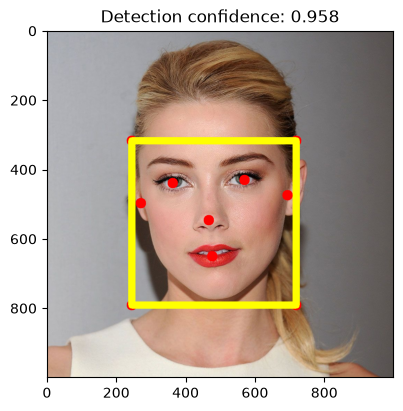

In [4]:
from landpy.pretrained_models import FaceTracker, FaceLandmarksDetector, FaceLandmarksIndices, FaceSegmentationDetector, ExpressionDetector
debugger = Debugger(visual_debug=True)
tracker = FaceTracker()
faces = tracker.detect_faces(photo, threshold=.5, top_k=1)
assert faces, 'No face detected; try a closer, front-facing portrait.'
face = faces[0]
(photo + face.face_box + face.face_points).show(f'Detection confidence: {face.p:.3f}')
region = face.face_box.copy().expand(1.25)
working = photo.copy().zoom(region, save_trace=True)

### 3. Find the points that anchor the effect 📍

The mesh model expects an already cropped face. It returns landmarks in **crop pixel coordinates**, plus a presence probability. That probability is separate from the earlier detection confidence. The default mesh has 478 points; legacy weights return 468. The wrappers handle model resizing and map the predictions back for us.

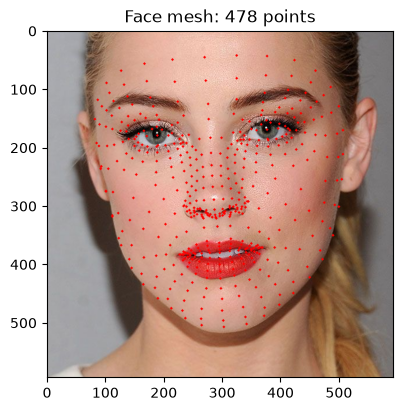

Mesh presence: 1.0


In [5]:
landmarks, presence = FaceLandmarksDetector().detect_face_landmarks(working)
preview = working.copy()
preview.ADDED_POINTS_RADIOUS = .3
mesh_preview = preview + landmarks
mesh_preview.show(f'Face mesh: {len(landmarks.get_marks())} points');
print('Mesh presence:', round(presence, 4))

### 4. Turn the lip outline into a paint mask 🎨

`LIPS` selects an ordered outline from the mesh. `to_heat()` fills that polygon: 1 permits the effect, 0 protects the background. This is a filled outer-lip region, not a detailed cosmetic segmentation; an open mouth can need a more careful mask.

The debugger compares the actual crop and mask. Check this **before** applying color: a misplaced mask will produce a misplaced effect, however nice the color is.

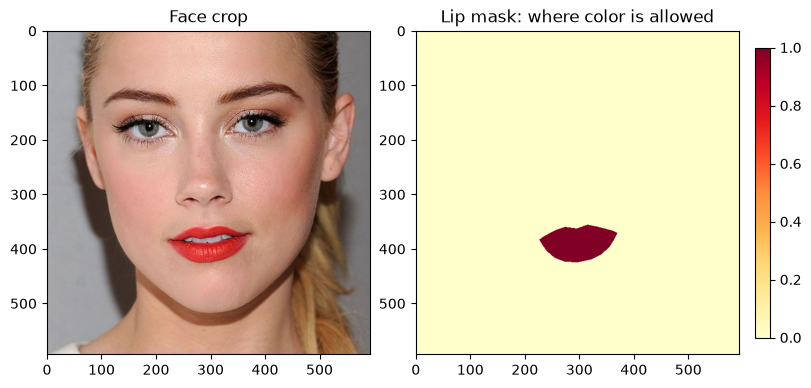

In [6]:
lips = landmarks[FaceLandmarksIndices.LIPS].to_heat()
debugger.log_images(
    [working.get_image(), lips.get_heat()],
    ['Face crop', 'Lip mask: where color is allowed'],
    [Debugger.LogTypes.IMAGE, Debugger.LogTypes.HEAT],
);

### 5. Edit the crop, then retrace it home 🪄

`copy(copy_trace=True)` keeps the recorded crop on an independent copy. A plain `copy()` drops history by default, so there would be no route to retrace. The filter blends toward rose at 65% strength wherever the mask is 1.

We save a debugger snapshot **before** retracing. `save_image()` copies the pixels, so that snapshot stays a crop even after the object returns to full-photo size. `retrace()` pastes the edited crop into the saved canvas. It does not erase the lip color—that would be the job of checkpoint undo.

In this sample the original lips are red, so the rose tint is easy to compare. The filled mask also colors the small mouth opening; this simple effect demonstrates placement rather than realistic virtual makeup.

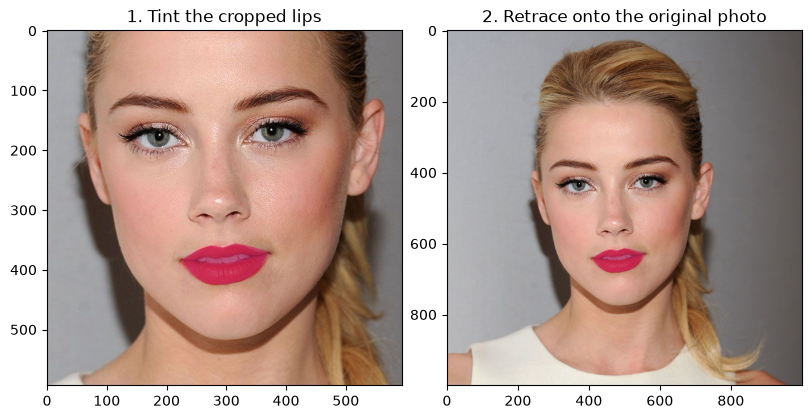

In [7]:
colored = working.copy(copy_trace=True).implant_filter(Filter('#c32660', .65), lips)
debugger.save_image(colored.get_image(), '1. Tint the cropped lips')
colored.retrace()
debugger.save_image(colored.get_image(), '2. Retrace onto the original photo')
debugger.log_saved_images();

### 6. See the complete AR result

The effect is deliberately local: the lip region changes while the portrait remains on its original canvas. This is the payoff from notebook 1. In a frame-by-frame AR application, you would repeat detection and placement for new frames; the historical `FaceTracker` name does not imply temporal tracking or smoothing.

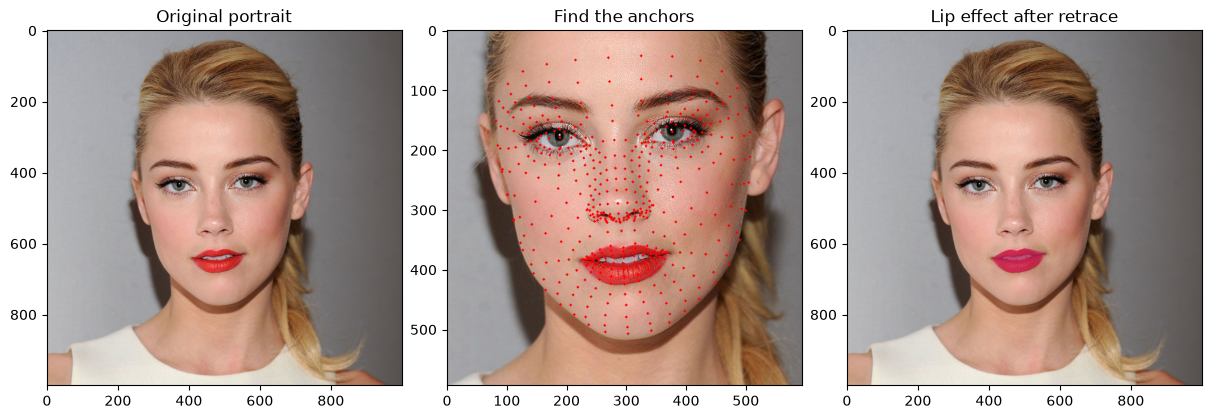

In [8]:
debugger.log_images(
    [photo.get_image(), mesh_preview.get_image(), colored.get_image()],
    ['Original portrait', 'Find the anchors', 'Lip effect after retrace'],
    [Debugger.LogTypes.IMAGE] * 3,
);

### 7. Another placement strategy: segment the full photo

A polygon is one way to select pixels; a segmentation model can supply a soft mask instead. Here we intentionally run segmentation on **the full photo**, then apply a teal filter to that same photo. There is no crop to retrace in this branch. The model output is resized to the photo dimensions; inspect it rather than assuming every predicted boundary is correct.

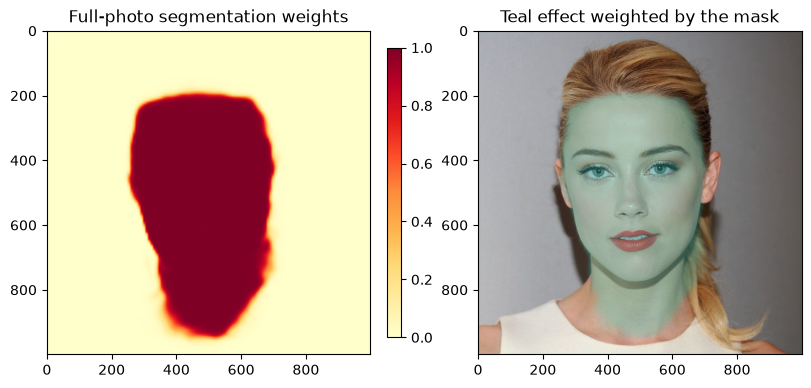

In [9]:
segmenter = FaceSegmentationDetector()
segmentation = segmenter.detect_face_segmentation(photo)
segmented_effect = photo.copy().implant_filter(Filter('#35c8bb', .35), segmentation)
debugger.log_images(
    [segmentation.get_heat(), segmented_effect.get_image()],
    ['Full-photo segmentation weights', 'Teal effect weighted by the mask'],
    [Debugger.LogTypes.HEAT, Debugger.LogTypes.IMAGE],
);

### 8. Optional side experiment: expression scores

This is separate from the placement workflow above. The original expression model accepts the **face crop** and returns seven class scores in `output_labels` order. These are model outputs, not a reliable measurement of feelings or intentions. You do not need them to create the AR effect.

The segmentation and expression weights are preserved historical assets with incomplete upstream/license records; see the [model notes](https://github.com/bateni1380/landpy/blob/master/docs/models.md) before reuse. The newer mesh and the original detectors have different input contracts; the wrappers handle them individually.

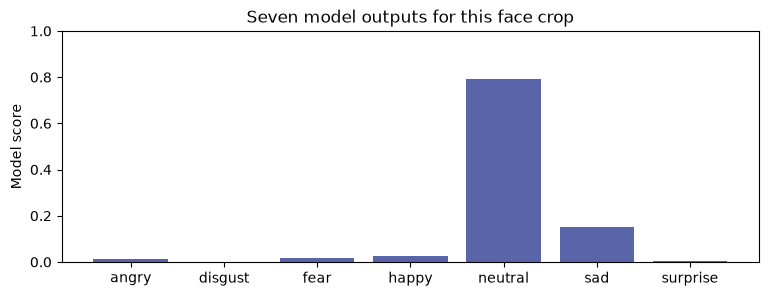

In [10]:
expression = ExpressionDetector()
scores = expression.detect_expression(working)[0]
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(expression.output_labels, scores, color='#5965a8')
ax.set(ylabel='Model score', ylim=(0, 1), title='Seven model outputs for this face crop')
plt.show();

## Checks: did the edit return safely?

These checks verify coordinates, output ranges, and that inference left our source photo unchanged. They check this example’s mechanics, not accuracy across different people, poses or lighting.

In [11]:
assert len(landmarks.get_marks()) in (468, 478)
assert landmarks.shape == working.shape
assert lips.shape == working.shape
assert segmentation.shape == photo.shape
assert 0 <= presence <= 1
assert scores.shape == (7,)
np.testing.assert_allclose(scores.sum(), 1, atol=1e-4)
np.testing.assert_array_equal(photo.get_image(), original)
assert colored.shape == photo.shape
assert np.any(colored.get_image() != original)
np.testing.assert_array_equal(colored.get_image()[0, 0], original[0, 0])
print('Effect returned to the photo; source pixels and canvas dimensions are preserved.')

Effect returned to the photo; source pixels and canvas dimensions are preserved.


## Your next effect 🚀

Try your own portrait, then change `Filter`’s color and ratio. Keep the same **crop → landmarks → mask → edit → retrace** loop. If the effect misses its target, inspect the face crop and lip mask first. For exact before/after restoration, checkpoint before cropping and use `undo()`.

You now have the core pieces for small AR experiments: model predictions choose a region, masks control the blend, and **retrace brings the edit home**. For a transparent sticker, reuse notebook 6’s `implant_image` with a region derived from landmarks.

[Back to the tutorial journey](https://github.com/bateni1380/landpy/tree/master/tutorials) · [API guide](https://github.com/bateni1380/landpy/blob/master/docs/api.md)

[← Previous lesson](https://github.com/bateni1380/landpy/blob/master/tutorials/7-model-wrappers.ipynb)